# FUTURE_ML_02: Support Ticket Classification

**Future Interns · Machine Learning Track · Task 2**

**Business problem.** A support team receives hundreds of tickets a day. Agents lose time reading each one, deciding which team should handle it, and guessing how urgent it is. This notebook builds a system that reads a ticket and returns:

1. a **category** (which team should handle it), and
2. a **priority** (High / Medium / Low), tuned so urgent tickets are rarely missed.

**Workflow:** data → cleaning and tokenization → EDA → category models → priority logic → evaluation → error analysis → business insights → a working `triage_ticket()` function.

> **Data note.** This notebook runs on a **simulated** ticket history (with deliberately messy records) so it works with no downloads. See the README for how to plug in a real dataset.

In [1]:
import re, json, random, textwrap, warnings, time, os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, precision_score, recall_score)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# ------------------------- Configuration -------------------------
DATA_PATH    = None                  # e.g. "tickets.csv". None = use the simulated data below
TEXT_COLS    = ["subject", "body"]   # text column(s) used by the model
CATEGORY_COL = "category"
PRIORITY_COL = "priority"
PRIORITY_MAP = {"critical": "High", "urgent": "High", "high": "High",
                "medium": "Medium", "normal": "Medium", "low": "Low"}
HIGH_RECALL_TARGET = 0.95            # business rule: catch at least 95% of High tickets
# -----------------------------------------------------------------

BLUE, GRAY, DARK = "#2563eb", "#9ca3af", "#1f2937"
PRI_COLORS = {"High": "#dc2626", "Medium": "#f59e0b", "Low": "#9ca3af"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
})
for folder in ("images", "outputs", "data"):
    os.makedirs(folder, exist_ok=True)
print("Setup complete.")

Setup complete.


## 1. The data

Real ticket exports are messy, so the simulated history includes the problems you would meet in practice: duplicate tickets, empty bodies, HTML leftovers, email signatures, inconsistent category labels, typos, ALL-CAPS and unpunctuated messages, tickets that mention two problems, a few mislabelled tickets, and people who write "URGENT" on trivial requests. One week also contains an outage that floods the queue with Technical tickets.

In [2]:
CATEGORIES = ["Billing & Payments", "Technical Issue", "Account & Login",
              "Shipping & Delivery", "Returns & Refunds", "General Inquiry"]
PRIORITIES = ["High", "Medium", "Low"]

FIRST_NAMES = ["Sam", "Alex", "Priya", "Jordan", "Maria", "Chen", "Fatima", "Liam", "Noah", "Aisha", "Diego", "Emma"]
PRODUCTS = ["wireless headphones", "standing desk", "smart watch", "laptop stand", "coffee maker",
            "yoga mat", "phone case", "desk lamp", "backpack", "air fryer"]
FEATURES = ["dashboard", "mobile app", "checkout page", "search bar", "notification settings",
            "export tool", "payment page", "profile page"]
AMOUNTS = ["$19.99", "$49.00", "$120.50", "$8.99", "$250.00", "$75.25"]
DAYS = ["2", "3", "5", "7", "10", "14"]

# Ticket sentences by category and severity (severe / normal / mild)
POOL = {
 "Billing & Payments": {
  "severe": ["I was charged {amount} twice for the same order and need this fixed",
             "There is an unauthorized charge of {amount} on my card that I did not make",
             "My payment was taken but the order shows as unpaid and the money has left my bank account"],
  "normal": ["My invoice shows the wrong amount, I was billed {amount} instead of the price on the website",
             "The discount code was not applied and I paid full price",
             "I need a copy of my invoice for last month",
             "My card was declined at checkout but my bank says the card is fine",
             "Please update the billing address on my subscription"],
  "mild":   ["Could you explain the extra line on my latest invoice?",
             "How can I change my payment method for next month?",
             "Do you accept bank transfers as a payment option?"]},
 "Technical Issue": {
  "severe": ["The whole {feature} is down and none of our team can work",
             "The app crashes every time I open it and I lose all my data",
             "Our integration has been failing since this morning and orders are not syncing"],
  "normal": ["The {feature} keeps freezing when I try to upload a file",
             "I get an error message when I click on the {feature}",
             "The page loads very slowly and sometimes times out",
             "The {feature} is not showing my latest changes after I refresh"],
  "mild":   ["The {feature} looks misaligned on my tablet screen",
             "Is there a way to change the dark mode colours in the app?",
             "A small typo appears on the {feature} text"]},
 "Account & Login": {
  "severe": ["I think my account has been hacked, there are logins from a country I have never visited",
             "I am locked out of my account and have a deadline",
             "Someone changed my password and email address and I cannot log in"],
  "normal": ["I did not receive the password reset email",
             "The verification code never arrives on my phone",
             "I cannot log in on the mobile app but the website works",
             "Please merge my two accounts into one",
             "I want to change the email address on my account"],
  "mild":   ["How do I update my display name?",
             "Can I turn on two factor authentication for my profile?",
             "How do I delete my old profile photo?"]},
 "Shipping & Delivery": {
  "severe": ["My {product} was supposed to arrive {days} days ago and tracking says it is lost",
             "The package was marked as delivered but nothing arrived and it was a gift",
             "The delivery confirmation shows the wrong address and my parcel is going to a stranger"],
  "normal": ["My order has been stuck in transit for {days} days",
             "The tracking number does not show any updates",
             "The courier left my parcel at the wrong door",
             "The box of my {product} arrived crushed"],
  "mild":   ["Can I change the delivery date for my next order?",
             "What are your delivery times to my area?",
             "Do you ship to other countries?"]},
 "Returns & Refunds": {
  "severe": ["I returned the {product} {days} days ago and still have not received my refund of {amount}",
             "I was sent a defective {product} that overheats and I am worried it is a safety risk",
             "My refund was rejected even though I returned the item within the return window"],
  "normal": ["I would like to return the {product}, it does not fit as expected",
             "The {product} I received is broken, please send a replacement",
             "How do I print a return label for my order?",
             "I received the wrong item, I ordered a {product}"],
  "mild":   ["What is your return policy for opened items?",
             "Can I exchange the {product} for another colour?",
             "Is the return shipping free?"]},
 "General Inquiry": {
  "severe": ["I have a media deadline and need to speak to someone about a partnership",
             "Our company wants to place a very large order and needs a quote"],
  "normal": ["Do you offer a business plan for teams?",
             "I would like to know whether the {product} is compatible with my setup",
             "Can someone call me back about wholesale pricing?"],
  "mild":   ["I just wanted to say thank you, your support was great",
             "Do you have a store location near me?",
             "Is there a newsletter I can sign up for?",
             "Where can I find your product catalogue?",
             "Just sharing feedback: the new website design looks great"]},
}
SUBJECTS = {
 "Billing & Payments": ["Billing question", "Charge on my card", "Invoice issue", "Payment problem", "Wrong amount billed"],
 "Technical Issue":    ["App problem", "Website error", "Something is not working", "Bug report", "Feature not loading"],
 "Account & Login":    ["Cannot log in", "Account access", "Password reset", "Account security", "Profile settings"],
 "Shipping & Delivery":["Where is my order", "Delivery problem", "Tracking question", "Parcel issue", "Shipping delay"],
 "Returns & Refunds":  ["Return request", "Refund status", "Wrong item received", "Replacement needed", "Exchange question"],
 "General Inquiry":    ["Quick question", "Product information", "Feedback", "Partnership enquiry", "Information request"],
}
GENERIC_SUBJECTS = ["Help", "Question", "Support request", "Re: my issue", "Hello", "Need assistance"]
URGENCY = {
 "High":   ["This is urgent.", "Please help ASAP!", "I need this resolved immediately.",
            "This is a critical issue for me.", "Please escalate this.", "Need a fix today please."],
 "Medium": ["Please let me know when you can.", "I would appreciate an update soon.",
            "Thanks in advance for the help.", ""],
 "Low":    ["No rush at all.", "Whenever you get a chance.", "Just curious.", "Thanks!", ""],
}
# how often each category produces High / Medium / Low tickets
PRIORITY_PROBS = {
 "Billing & Payments": [0.30, 0.45, 0.25], "Technical Issue": [0.35, 0.45, 0.20],
 "Account & Login":    [0.40, 0.40, 0.20], "Shipping & Delivery": [0.25, 0.50, 0.25],
 "Returns & Refunds":  [0.15, 0.50, 0.35], "General Inquiry": [0.03, 0.22, 0.75],
}
SEVERITY_FOR = {"High":   ["severe"] * 8 + ["normal"] * 2,
                "Medium": ["normal"] * 8 + ["severe"] + ["mild"],
                "Low":    ["mild"] * 6 + ["normal"] * 4}
NEIGHBOURS = {"Billing & Payments": ["Returns & Refunds", "Account & Login"],
              "Technical Issue": ["Account & Login", "General Inquiry"],
              "Account & Login": ["Technical Issue", "Billing & Payments"],
              "Shipping & Delivery": ["Returns & Refunds", "General Inquiry"],
              "Returns & Refunds": ["Shipping & Delivery", "Billing & Payments"],
              "General Inquiry": ["Technical Issue", "Billing & Payments", "Shipping & Delivery"]}

def fill(rng, template):
    return template.format(product=rng.choice(PRODUCTS), feature=rng.choice(FEATURES),
                           amount=rng.choice(AMOUNTS), days=rng.choice(DAYS))

def sentence(rng, template):
    s = fill(rng, template)
    return s if s.endswith("?") else s + "."

def add_typos(rng, text, k):
    words = text.split(" ")
    idx = [i for i, w in enumerate(words) if len(w) > 4 and w.isalpha()]
    for i in rng.sample(idx, min(k, len(idx))):
        w = words[i]; j = rng.randrange(1, len(w) - 2)
        words[i] = w[:j] + w[j + 1] + w[j] + w[j + 2:]
    return " ".join(words)

def make_ticket(rng, category, priority, created_at):
    severity = rng.choice(SEVERITY_FOR[priority])
    parts = [sentence(rng, rng.choice(POOL[category][severity]))]
    if rng.random() < 0.25:                      # second, unrelated problem in the same ticket
        other = rng.choice([c for c in CATEGORIES if c != category])
        extra = sentence(rng, rng.choice(POOL[other]["normal"] + POOL[other]["mild"]))
        extra = extra if extra.startswith("I ") else extra[0].lower() + extra[1:]
        parts.append(rng.choice(["Also,", "By the way,", "Also"]) + " " + extra)
    tone = priority                              # people sometimes mis-state urgency
    if priority == "High" and rng.random() < 0.10: tone = "Low"
    elif priority == "Low" and rng.random() < 0.08: tone = "High"
    elif priority == "Medium" and rng.random() < 0.05: tone = rng.choice(["High", "Low"])
    urgency = rng.choice(URGENCY[tone])
    if urgency: parts.append(urgency)
    name = rng.choice(FIRST_NAMES)
    closer = rng.choice(["", "Thanks", "Thank you", f"Regards,\n{name}", f"Best,\n{name}", "Sent from my iPhone"])
    body = (rng.choice(["Hi,", "Hello team,", "Hi support,", "Good morning,", "", ""]) + " " + " ".join(parts)).strip()
    body = body + ("\n" + closer if closer else "")
    # --- noise ---
    if rng.random() < 0.25: body = add_typos(rng, body, rng.randint(1, 3))
    if rng.random() < 0.15: body = re.sub(r"[.,!?]", "", body)
    if rng.random() < 0.20: body = body.lower()
    if rng.random() < 0.03: body = body.replace(". ", ".<br>")
    subject = rng.choice(GENERIC_SUBJECTS) if rng.random() < 0.15 else rng.choice(SUBJECTS[category])
    if (priority == "High" and rng.random() < 0.30) or (priority == "Low" and rng.random() < 0.05):
        subject = "URGENT: " + subject
    label = rng.choice(NEIGHBOURS[category]) if rng.random() < 0.03 else category   # ~3% mislabelled
    return {"created_at": created_at, "subject": subject, "body": body, "category": label, "priority": priority}

def make_dataset(n_base=5800, n_outage=150):
    rng = random.Random(SEED); nrng = np.random.RandomState(SEED)
    days = pd.date_range("2025-01-01", "2025-12-31")
    w = np.where(days.dayofweek < 5, 1.0, np.where(days.dayofweek == 5, 0.45, 0.35)); w = w / w.sum()
    dates = nrng.choice(days, size=n_base, p=w)
    cat_w = [0.20, 0.22, 0.16, 0.18, 0.15, 0.09]
    rows = []
    for i in range(n_base):
        cat = rng.choices(CATEGORIES, cat_w)[0]
        pri = rng.choices(PRIORITIES, PRIORITY_PROBS[cat])[0]
        rows.append(make_ticket(rng, cat, pri, pd.Timestamp(dates[i])))
    outage_days = pd.date_range("2025-09-15", "2025-09-21")          # outage week
    for i in range(n_outage):
        rows.append(make_ticket(rng, "Technical Issue", "High", rng.choice(outage_days)))
    df = pd.DataFrame(rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
    df = pd.concat([df, df.sample(frac=0.015, random_state=1)]).reset_index(drop=True)       # duplicates
    df.loc[df.sample(frac=0.012, random_state=2).index, "body"] = np.nan                     # empty bodies
    var = df.sample(frac=0.02, random_state=3).index                                         # label spelling
    df.loc[var, "category"] = df.loc[var, "category"].apply(lambda c: rng.choice([c.upper(), c.lower(), " " + c + " "]))
    df = df.sort_values("created_at").reset_index(drop=True)
    df.insert(0, "ticket_id", [f"T{100000 + i}" for i in range(len(df))])
    return df

if DATA_PATH is None:
    raw = make_dataset()
    raw.to_csv("data/support_tickets_simulated.csv", index=False)
else:
    raw = pd.read_csv(DATA_PATH)
    raw["subject"] = raw[TEXT_COLS[0]]
    raw["body"] = raw[TEXT_COLS[1]] if len(TEXT_COLS) > 1 else ""
    raw["category"] = raw[CATEGORY_COL]
    raw["priority"] = raw[PRIORITY_COL].astype(str).str.strip().str.lower().map(PRIORITY_MAP)
    if "created_at" not in raw.columns: raw["created_at"] = pd.NaT
    raw["created_at"] = pd.to_datetime(raw["created_at"], errors="coerce")

print(f"Raw tickets: {len(raw):,}")
raw[["ticket_id", "created_at", "subject", "body", "category", "priority"]].head(6)

Raw tickets: 6,039


,ticket_id,created_at,subject,body,category,priority
0,T100000,2025-01-01,Parcel issue,The box of my laptop stand arrived crushed I would apprecitae an update soon,Shipping & Delivery,Medium
1,T100001,2025-01-01,Cannot log in,"hi, i think my account has been hacked, there are logins from a country i have never v...",Account & Login,High
2,T100002,2025-01-01,Exchange question,"I would like to return the desk lamp, it does not fit as expected. Thanks in advance f...",Returns & Refunds,Medium
3,T100003,2025-01-01,Payment problem,"Good morning, There is an unauthorized charge of $49.00 on my card that I did not make...",Billing & Payments,Medium
4,T100004,2025-01-01,Re: my issue,"The proifle page is not showing my latest chnages after I refresh. By the way, the ver...",Technical Issue,Low
5,T100005,2025-01-01,Refund status,"Hi, I received the wrnog item, I ordered a standing desk.\nBest,\nDiego",Returns & Refunds,Medium


## 2. Data cleaning and text preparation

First audit what is wrong, then fix it, then turn each ticket into clean tokens. Every fix is counted so nothing happens silently.

In [3]:
body_blank = raw["body"].fillna("").str.strip().eq("")
audit = pd.Series({
    "Total rows": len(raw),
    "Empty / missing body": int(body_blank.sum()),
    "Exact duplicate tickets (subject + body)": int(raw.duplicated(subset=["subject", "body"]).sum()),
    "Rows with HTML leftovers (<br>)": int(raw["body"].fillna("").str.contains("<br", case=False).sum()),
    "Rows with 'Sent from my ...' signatures": int(raw["body"].fillna("").str.contains("sent from my", case=False).sum()),
    "Distinct category spellings (before)": raw["category"].nunique(),
    "Distinct category names (after normalising case/spaces)": raw["category"].astype(str).str.strip().str.lower().nunique(),
}).to_frame("count")
audit

,count
Total rows,6039
Empty / missing body,72
Exact duplicate tickets (subject + body),136
Rows with HTML leftovers (<br>),115
Rows with 'Sent from my ...' signatures,1007
Distinct category spellings (before),24
Distinct category names (after normalising case/spaces),6


In [4]:
# ---------- text preparation (also reused by triage_ticket() at the end) ----------
KEEP = {"not", "no", "never", "cannot", "nothing", "none", "nor"}          # negations carry meaning
BOILERPLATE = {"hi", "hello", "hey", "team", "support", "thanks", "thank", "regards", "best",
               "morning", "please", "dear", "cheers"}
STOP = (set(ENGLISH_STOP_WORDS) - KEEP) | BOILERPLATE

def strip_boilerplate(text):
    t = re.sub(r"<br\s*/?>", " ", str(text), flags=re.I)                    # HTML line breaks
    t = re.sub(r"<[^>]+>", " ", t)                                          # any other tag
    t = re.sub(r"sent from my \w+", " ", t, flags=re.I)                     # mobile signature
    t = re.sub(r"(regards|best|thanks|thank you|cheers),?\s*\n\s*[A-Za-z]+\s*$", " ", t, flags=re.I)  # name sign-off
    return re.sub(r"\s+", " ", t).strip()

def prepare_text(subject, body):
    """Subject + body -> one lowercase string with boilerplate removed."""
    subject = "" if pd.isna(subject) else str(subject)
    body = "" if pd.isna(body) else str(body)
    return strip_boilerplate(subject + ". " + body).lower()

def light_stem(w):
    """Tiny suffix stripper so 'charged', 'charging', 'charges' share one token."""
    if len(w) <= 3: return w
    for suf, rep in (("ies", "y"), ("ing", ""), ("ed", ""), ("es", ""), ("ly", ""), ("s", "")):
        if w.endswith(suf) and len(w) - len(suf) >= 3 and not (suf == "s" and w.endswith("ss")):
            w = w[:-len(suf)] + rep
            break
    return w[:-1] if w.endswith("e") and len(w) > 3 else w

def clean_text(text):
    t = re.sub(r"\$\s?\d+(?:[.,]\d+)?", " moneyamount ", text)             # keep 'there is a money amount' as a signal
    t = re.sub(r"\d+", " ", t)
    return " ".join(light_stem(w) for w in re.findall(r"[a-z]+", t) if len(w) > 1 and w not in STOP)

df = raw.copy()
log = [("Rows at start", len(df))]

# 1. consistent category names (most common spelling wins)
cat_norm = df["category"].astype(str).str.strip()
spelling = cat_norm.groupby(cat_norm.str.lower()).agg(lambda s: s.value_counts().idxmax())
df["category"] = cat_norm.str.lower().map(spelling)

# 2. duplicates (the same ticket in train AND test would inflate the scores)
n = len(df); df = df.drop_duplicates(subset=["subject", "body"]).reset_index(drop=True)
log.append(("Duplicate tickets removed", n - len(df)))

# 3. text preparation
df["text_lower"] = [prepare_text(s, b) for s, b in zip(df["subject"], df["body"])]
df["clean_text"] = df["text_lower"].map(clean_text)
df["n_words"] = df["text_lower"].str.split().str.len()

# 4. tickets with almost no usable text cannot be classified
n = len(df); df = df[df["clean_text"].str.split().str.len() >= 3].reset_index(drop=True)
log.append(("Tickets with < 3 usable words dropped", n - len(df)))
log.append(("Rows after cleaning", len(df)))

print(pd.DataFrame(log, columns=["step", "rows"]).to_string(index=False))
print("\nCategories now:", sorted(df["category"].unique()))
print("\nExample of the text pipeline:")
ex = df.sample(1, random_state=7).iloc[0]
print("  raw    :", repr(raw.loc[raw["ticket_id"] == ex["ticket_id"], "body"].iloc[0])[:150])
print("  cleaned:", ex["clean_text"][:150])

                                 step  rows
                        Rows at start  6039
            Duplicate tickets removed   136
Tickets with < 3 usable words dropped    30
                  Rows after cleaning  5873

Categories now: ['Account & Login', 'Billing & Payments', 'General Inquiry', 'Returns & Refunds', 'Shipping & Delivery', 'Technical Issue']

Example of the text pipeline:
  raw    : 'Hi, My card was declined at checkout but my bank says the card is fine.\nThank you'
  cleaned: request card declin checkout bank say card fin


## 3. Exploratory analysis

Largest queue : Technical Issue (22% of tickets)
Overall mix   : High 28%, Medium 43%, Low 29%
Most urgent   : Technical Issue (42% High)  |  Least urgent: General Inquiry (4% High)


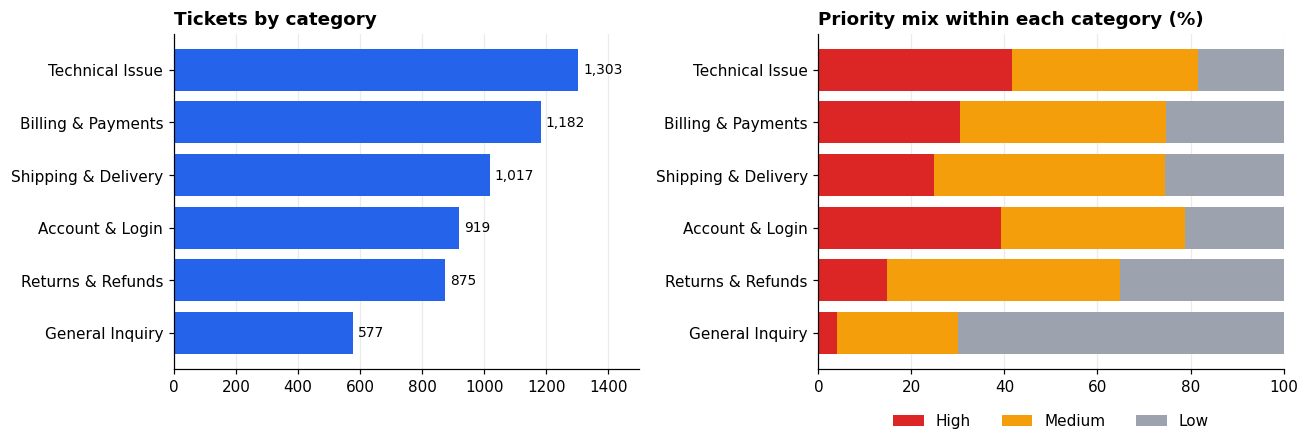

In [5]:
cat_counts = df["category"].value_counts()
mix = pd.crosstab(df["category"], df["priority"], normalize="index")[PRIORITIES] * 100
mix = mix.loc[cat_counts.index]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh(cat_counts.index[::-1], cat_counts.values[::-1], color=BLUE)
for i, v in enumerate(cat_counts.values[::-1]):
    ax[0].text(v + 15, i, f"{v:,}", va="center", fontsize=9)
ax[0].set_title("Tickets by category"); ax[0].set_xlim(0, cat_counts.max() * 1.15); ax[0].grid(axis="y", visible=False)

left = np.zeros(len(mix))
for p in PRIORITIES:
    ax[1].barh(mix.index[::-1], mix[p].values[::-1], left=left[::-1], color=PRI_COLORS[p], label=p)
    left += mix[p].values
ax[1].set_title("Priority mix within each category (%)"); ax[1].set_xlim(0, 100)
ax[1].legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.22), frameon=False); ax[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/01_category_priority_mix.png", bbox_inches="tight"); plt.show()

print(f"Largest queue : {cat_counts.index[0]} ({cat_counts.iloc[0] / len(df):.0%} of tickets)")
print(f"Overall mix   : " + ", ".join(f"{p} {(df['priority'] == p).mean():.0%}" for p in PRIORITIES))
print(f"Most urgent   : {mix['High'].idxmax()} ({mix['High'].max():.0f}% High)  |  Least urgent: {mix['High'].idxmin()} ({mix['High'].min():.0f}% High)")

Peak week (21 Sep 2025): 243 tickets vs a typical week of 109 (+123%).
In that week 66% of tickets were 'Technical Issue' and 72% were High priority.


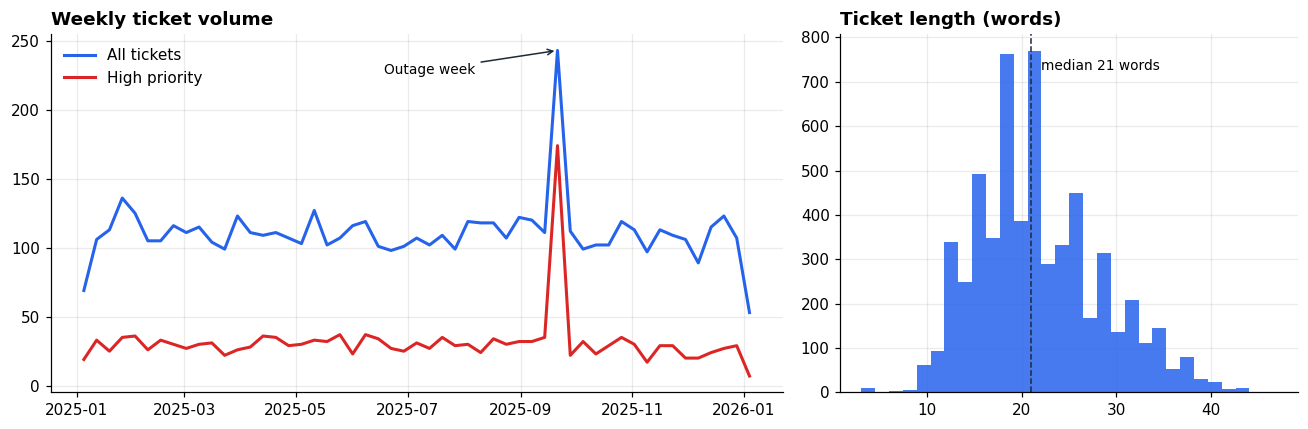

In [6]:
weekly = df.set_index("created_at").resample("W").agg(total=("ticket_id", "count"),
                                                      high=("priority", lambda s: (s == "High").sum()))
peak = weekly["total"].idxmax(); typical = weekly["total"].drop(peak).median()

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].plot(weekly.index, weekly["total"], color=BLUE, lw=2, label="All tickets")
ax[0].plot(weekly.index, weekly["high"], color=PRI_COLORS["High"], lw=2, label="High priority")
ax[0].annotate("Outage week", xy=(peak, weekly.loc[peak, "total"]), xytext=(peak - pd.Timedelta(days=95), weekly["total"].max() * 0.93),
               arrowprops=dict(arrowstyle="->", color=DARK), fontsize=9)
ax[0].set_title("Weekly ticket volume"); ax[0].legend(frameon=False, loc="upper left")
ax[1].hist(df["n_words"].clip(upper=60), bins=30, color=BLUE, alpha=.85)
ax[1].axvline(df["n_words"].median(), color=DARK, ls="--", lw=1)
ax[1].text(df["n_words"].median() + 1, ax[1].get_ylim()[1] * 0.9, f"median {df['n_words'].median():.0f} words", fontsize=9)
ax[1].set_title("Ticket length (words)")
plt.tight_layout(); plt.savefig("images/02_volume_and_length.png", bbox_inches="tight"); plt.show()

print(f"Peak week ({peak:%d %b %Y}): {weekly.loc[peak, 'total']} tickets vs a typical week of {typical:.0f} "
      f"(+{weekly.loc[peak, 'total'] / typical - 1:.0%}).")
wk = df[(df["created_at"] >= peak - pd.Timedelta(days=6)) & (df["created_at"] <= peak)]
print(f"In that week {wk['category'].value_counts(normalize=True).iloc[0]:.0%} of tickets were '{wk['category'].value_counts().index[0]}' "
      f"and {(wk['priority'] == 'High').mean():.0%} were High priority.")

## 4. Category classification

**Split.** 80% train / 20% test, stratified on category and priority together. Duplicates were removed first, so no ticket appears on both sides. The test set is used **once**, at the end.

**Model comparison.** Five models are compared with 5-fold cross-validation on the training set only. TF-IDF is fitted *inside* each fold, so the validation fold never influences the vocabulary. The score to watch is **macro-F1**, which gives each category equal weight, so small queues like General Inquiry count as much as large ones.

Train: 4,698 tickets   Test: 1,175 tickets


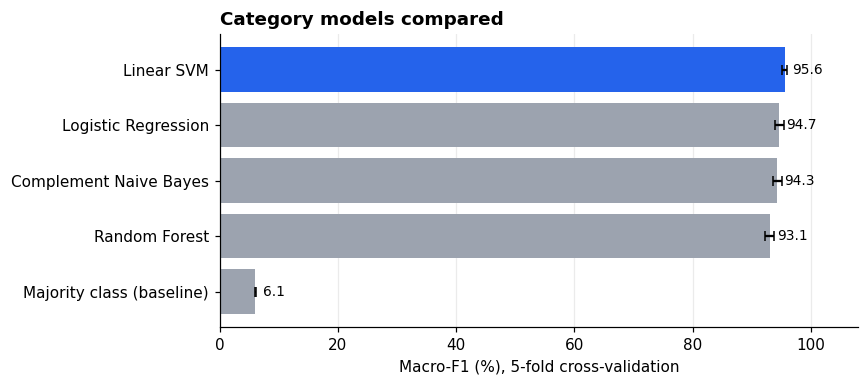

,accuracy,macro_f1,macro_f1_std
model,,,
Linear SVM,95.8,95.6,0.4
Logistic Regression,94.9,94.7,0.8
Complement Naive Bayes,94.6,94.3,0.8
Random Forest,93.4,93.1,0.8
Majority class (baseline),22.2,6.1,0.0


In [7]:
strat = df["category"] + "|" + df["priority"]
train, test = train_test_split(df, test_size=0.20, stratify=strat, random_state=SEED)
print(f"Train: {len(train):,} tickets   Test: {len(test):,} tickets")

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

cat_models = {
    "Majority class (baseline)": DummyClassifier(strategy="most_frequent"),
    "Complement Naive Bayes":    ComplementNB(alpha=0.3),
    "Logistic Regression":       LogisticRegression(C=10, max_iter=2000),
    "Linear SVM":                LinearSVC(C=1.0),
    "Random Forest":             RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=SEED),
}
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, clf in cat_models.items():
    pipe = Pipeline([("tfidf", tfidf()), ("clf", clf)])
    cv = cross_validate(pipe, train["clean_text"], train["category"], cv=skf,
                        scoring=["accuracy", "f1_macro"])
    rows.append({"model": name, "accuracy": cv["test_accuracy"].mean(),
                 "macro_f1": cv["test_f1_macro"].mean(), "macro_f1_std": cv["test_f1_macro"].std()})
cat_cv = pd.DataFrame(rows).set_index("model").sort_values("macro_f1", ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
order = cat_cv.index[::-1]
colors = [BLUE if m == cat_cv.index[0] else GRAY for m in order]
ax.barh(order, cat_cv.loc[order, "macro_f1"] * 100, xerr=cat_cv.loc[order, "macro_f1_std"] * 100, color=colors, capsize=3)
for i, m in enumerate(order):
    ax.text(cat_cv.loc[m, "macro_f1"] * 100 + 1.2, i, f"{cat_cv.loc[m, 'macro_f1'] * 100:.1f}", va="center", fontsize=9)
ax.set_xlim(0, 108); ax.set_xlabel("Macro-F1 (%), 5-fold cross-validation"); ax.set_title("Category models compared"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/03_category_model_comparison.png", bbox_inches="tight"); plt.show()

cat_cv_show = (cat_cv * 100).round(1)
cat_cv_show

In [8]:
# Tune the winning model with a small grid (still cross-validation on train only)
best_name = cat_cv.index[0]
best_clf = cat_models[best_name]
grids = {"Complement Naive Bayes": {"clf__alpha": [0.1, 0.3, 1.0]},
         "Logistic Regression":    {"clf__C": [1, 3, 10, 30]},
         "Linear SVM":             {"clf__C": [0.1, 0.3, 1, 3]}}
pipe = Pipeline([("tfidf", tfidf()), ("clf", best_clf)])
if best_name in grids:
    gs = GridSearchCV(pipe, grids[best_name], scoring="f1_macro", cv=skf, n_jobs=-1).fit(train["clean_text"], train["category"])
    pipe, tuned = gs.best_estimator_, gs.best_params_
else:
    tuned = {}
print(f"Selected model : {best_name}   tuned parameters: {tuned}")

# Linear SVM has no probabilities, so wrap it to get calibrated confidence scores
if not hasattr(pipe, "predict_proba"):
    pipe = CalibratedClassifierCV(pipe, cv=5)
cat_model = pipe.fit(train["clean_text"], train["category"])

test = test.copy()
proba = cat_model.predict_proba(test["clean_text"])
test["pred_category"] = cat_model.classes_[proba.argmax(1)]
test["cat_confidence"] = proba.max(1)

acc = accuracy_score(test["category"], test["pred_category"])
mf1 = f1_score(test["category"], test["pred_category"], average="macro")
base = accuracy_score(test["category"], [train["category"].mode()[0]] * len(test))
print(f"\nTEST  accuracy {acc:.1%}   macro-F1 {mf1:.1%}   (majority-class baseline accuracy {base:.1%})\n")

report_cat = pd.DataFrame(classification_report(test["category"], test["pred_category"], output_dict=True)).T
report_cat.loc[CATEGORIES + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3)

Selected model : Linear SVM   tuned parameters: {'clf__C': 0.3}

TEST  accuracy 96.4%   macro-F1 96.1%   (majority-class baseline accuracy 22.1%)


,precision,recall,f1-score,support
Billing & Payments,0.967,0.979,0.973,237.0
Technical Issue,0.963,0.988,0.975,260.0
Account & Login,0.973,0.962,0.967,184.0
Shipping & Delivery,0.947,0.975,0.961,203.0
Returns & Refunds,0.965,0.937,0.951,175.0
General Inquiry,0.981,0.905,0.942,116.0
macro avg,0.966,0.958,0.961,1175.0


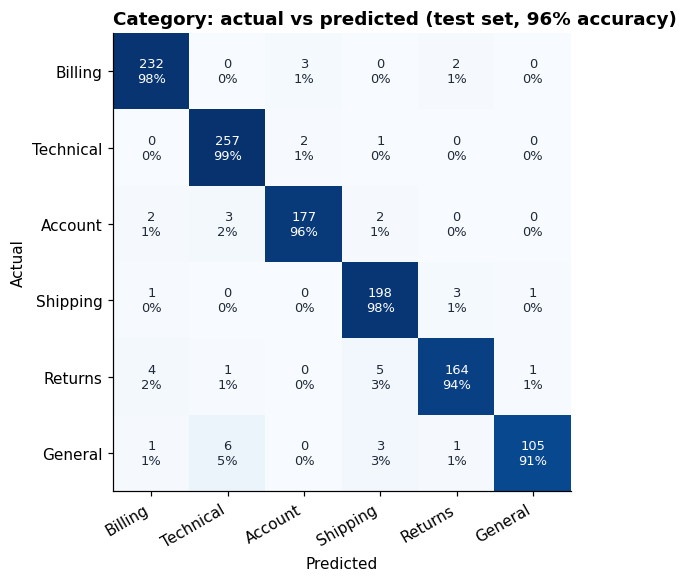

In [9]:
SHORT = {"Billing & Payments": "Billing", "Technical Issue": "Technical", "Account & Login": "Account",
         "Shipping & Delivery": "Shipping", "Returns & Refunds": "Returns", "General Inquiry": "General"}

def plot_confusion(y_true, y_pred, labels, names, title, path):
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    pct = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(6.4, 5.4))
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{cm[i, j]}\n{pct[i, j]:.0%}", ha="center", va="center", fontsize=8.5,
                    color="white" if pct[i, j] > 0.55 else DARK)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(names, rotation=30, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(names)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title); ax.grid(False)
    plt.tight_layout(); plt.savefig(path, bbox_inches="tight"); plt.show()
    return cm

cm_cat = plot_confusion(test["category"], test["pred_category"], CATEGORIES, [SHORT[c] for c in CATEGORIES],
                        f"Category: actual vs predicted (test set, {acc:.0%} accuracy)", "images/04_category_confusion.png")

## 5. Priority tagging

Priority is harder than category because the same words ("urgent") are used by people with trivial and serious problems. Four policies are compared on the training set with cross-validation:

| Policy | Idea |
|---|---|
| **A. Keyword rules** | What a manager would write by hand: urgency words → High, casual wording → Low, else Medium. No learning. |
| **B. ML (TF-IDF + Logistic Regression)** | Learns which words and phrases go with each priority. |
| **C. ML + critical-keyword override** | B, but words like *hacked*, *fraud*, *unauthorized*, *locked out* force High. |
| **D. ML + High-recall threshold** | B, but a ticket is flagged High whenever P(High) passes a threshold chosen so that at least 95% of truly High tickets are caught. |

**Why D?** Missing an urgent ticket (a hacked account, a double charge) costs far more than flagging a ticket as High that turns out to be Medium. So the policy is tuned for **High recall first**, then we look at what it costs in precision.

In [10]:
URGENCY_RE  = re.compile(r"\b(urgent|urgently|asap|immediately|critical|escalate|emergency|right away)\b")
CASUAL_RE   = re.compile(r"\b(no rush|whenever|just curious|just wondering|just wanted|how do i|how can i|can i|do you|is there|where can i)\b")
CRITICAL_RE = re.compile(r"(hack|unauthori[sz]ed|fraud|safety|overheat|locked out|stolen|data loss|lose all|charged .{0,30}twice|\btwice\b|is down|is lost|crash)")

def rule_priority(text):
    if URGENCY_RE.search(text) or CRITICAL_RE.search(text): return "High"
    if CASUAL_RE.search(text): return "Low"
    return "Medium"

def apply_threshold(proba, classes, t):
    """High if P(High) >= t, otherwise the more likely of the remaining classes."""
    classes = list(classes); hi = classes.index("High")
    others = [i for i in range(len(classes)) if i != hi]
    out = np.array([classes[others[k]] for k in proba[:, others].argmax(1)], dtype=object)
    out[proba[:, hi] >= t] = "High"
    return out

def priority_scores(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "macro_f1": f1_score(y_true, y_pred, average="macro"),
            "high_precision": precision_score(y_true, y_pred, labels=["High"], average=None, zero_division=0)[0],
            "high_recall": recall_score(y_true, y_pred, labels=["High"], average=None, zero_division=0)[0]}

pri_pipe = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=5, class_weight="balanced", max_iter=2000))])
y_tr = train["priority"].values
cv_proba = cross_val_predict(pri_pipe, train["clean_text"], y_tr, cv=skf, method="predict_proba")
PRI_CLASSES = np.array(sorted(PRIORITIES))                  # ['High', 'Low', 'Medium']

# Pick the threshold on cross-validated probabilities: the highest t that still catches >= 95% of High tickets
grid = np.round(np.arange(0.05, 0.71, 0.01), 2)
curve = pd.DataFrame([{"t": t, **{k: v for k, v in priority_scores(y_tr, apply_threshold(cv_proba, PRI_CLASSES, t)).items()
                                  if k.startswith("high")}} for t in grid])
ok = curve[curve["high_recall"] >= HIGH_RECALL_TARGET]
T_HIGH = float(ok["t"].max()) if len(ok) else float(curve.loc[curve["high_recall"].idxmax(), "t"])
print(f"Chosen High-priority threshold: P(High) >= {T_HIGH:.2f}\n")

b_pred = PRI_CLASSES[cv_proba.argmax(1)]
policies_cv = {
    "A. Keyword rules":                    train["text_lower"].map(rule_priority).values,
    "B. ML (argmax)":                      b_pred,
    "C. ML + critical-keyword override":   np.where(train["text_lower"].str.contains(CRITICAL_RE).values, "High", b_pred),
    "D. ML + High-recall threshold":       apply_threshold(cv_proba, PRI_CLASSES, T_HIGH),
}
pri_cv = pd.DataFrame({k: priority_scores(y_tr, v) for k, v in policies_cv.items()}).T
(pri_cv * 100).round(1).rename(columns={"accuracy": "accuracy %", "macro_f1": "macro-F1 %",
                                         "high_precision": "High precision %", "high_recall": "High recall %"})

Chosen High-priority threshold: P(High) >= 0.41


,accuracy %,macro-F1 %,High precision %,High recall %
A. Keyword rules,76.9,76.8,81.2,89.0
B. ML (argmax),88.6,88.7,92.5,94.7
C. ML + critical-keyword override,87.2,87.3,88.1,95.0
D. ML + High-recall threshold,88.5,88.5,91.7,95.0


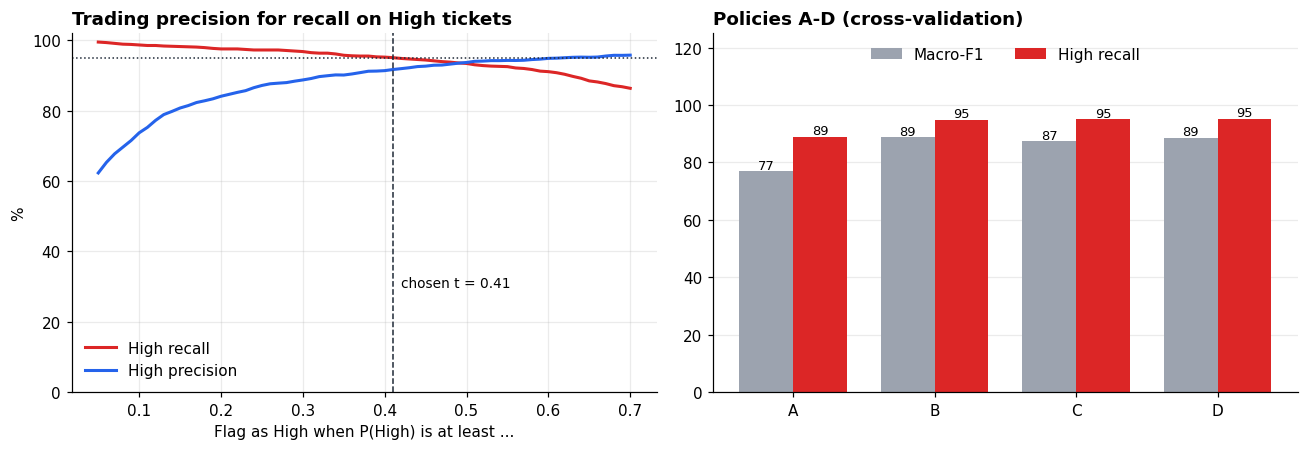

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(curve["t"], curve["high_recall"] * 100, color=PRI_COLORS["High"], lw=2, label="High recall")
ax[0].plot(curve["t"], curve["high_precision"] * 100, color=BLUE, lw=2, label="High precision")
ax[0].axhline(HIGH_RECALL_TARGET * 100, color=DARK, ls=":", lw=1); ax[0].axvline(T_HIGH, color=DARK, ls="--", lw=1)
ax[0].text(T_HIGH + 0.01, 30, f"chosen t = {T_HIGH:.2f}", fontsize=9)
ax[0].set_xlabel("Flag as High when P(High) is at least ..."); ax[0].set_ylabel("%"); ax[0].set_ylim(0, 102)
ax[0].set_title("Trading precision for recall on High tickets"); ax[0].legend(frameon=False, loc="lower left")

names = list(pri_cv.index); x = np.arange(len(names)); w = 0.38
ax[1].bar(x - w / 2, pri_cv["macro_f1"] * 100, w, color=GRAY, label="Macro-F1")
ax[1].bar(x + w / 2, pri_cv["high_recall"] * 100, w, color=PRI_COLORS["High"], label="High recall")
for i, n in enumerate(names):
    ax[1].text(i - w / 2, pri_cv.loc[n, "macro_f1"] * 100 + 1, f"{pri_cv.loc[n, 'macro_f1'] * 100:.0f}", ha="center", fontsize=8.5)
    ax[1].text(i + w / 2, pri_cv.loc[n, "high_recall"] * 100 + 1, f"{pri_cv.loc[n, 'high_recall'] * 100:.0f}", ha="center", fontsize=8.5)
ax[1].set_xticks(x); ax[1].set_xticklabels([n.split(". ")[0] for n in names]); ax[1].set_ylim(0, 125)
ax[1].set_title("Policies A-D (cross-validation)"); ax[1].legend(frameon=False, loc="upper center", ncol=2); ax[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/05_priority_policies.png", bbox_inches="tight"); plt.show()

In [12]:
# Fit on the full training set, then score every policy once on the untouched test set
pri_model = pri_pipe.fit(train["clean_text"], train["priority"])
p_test = pri_model.predict_proba(test["clean_text"])
test["p_high"] = p_test[:, list(pri_model.classes_).index("High")]
b_test = pri_model.classes_[p_test.argmax(1)]
policies_test = {
    "A. Keyword rules":                  test["text_lower"].map(rule_priority).values,
    "B. ML (argmax)":                    b_test,
    "C. ML + critical-keyword override": np.where(test["text_lower"].str.contains(CRITICAL_RE).values, "High", b_test),
    "D. ML + High-recall threshold":     apply_threshold(p_test, pri_model.classes_, T_HIGH),
}
pri_test = pd.DataFrame({k: priority_scores(test["priority"], v) for k, v in policies_test.items()}).T
test["pred_priority"] = policies_test["D. ML + High-recall threshold"]

print("TEST SET, all policies:")
display_tbl = (pri_test * 100).round(1).rename(columns={"accuracy": "accuracy %", "macro_f1": "macro-F1 %",
                                                         "high_precision": "High precision %", "high_recall": "High recall %"})
print(display_tbl.to_string())

d = pri_test.loc["D. ML + High-recall threshold"]; a = pri_test.loc["A. Keyword rules"]
n_high = (test["priority"] == "High").sum()
caught = ((test["priority"] == "High") & (test["pred_priority"] == "High")).sum()
flagged = (test["pred_priority"] == "High").sum()
print(f"\nPolicy D catches {caught} of {n_high} High tickets ({d['high_recall']:.0%}); "
      f"{flagged - caught} of the {flagged} tickets it flags are not truly High (precision {d['high_precision']:.0%}).")
print(f"Keyword rules alone catch {a['high_recall']:.0%} of High tickets.")

report_pri = pd.DataFrame(classification_report(test["priority"], test["pred_priority"], output_dict=True)).T
report_pri.loc[PRIORITIES + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3)

TEST SET, all policies:
                                   accuracy %  macro-F1 %  High precision %  High recall %
A. Keyword rules                         75.7        75.5              79.3           85.3
B. ML (argmax)                           88.5        88.5              90.8           94.6
C. ML + critical-keyword override        87.3        87.3              86.8           95.2
D. ML + High-recall threshold            88.3        88.2              90.5           94.3

Policy D catches 314 of 333 High tickets (94%); 33 of the 347 tickets it flags are not truly High (precision 90%).
Keyword rules alone catch 85% of High tickets.


,precision,recall,f1-score,support
High,0.905,0.943,0.924,333.0
Medium,0.904,0.866,0.885,501.0
Low,0.830,0.848,0.839,341.0
macro avg,0.880,0.886,0.882,1175.0


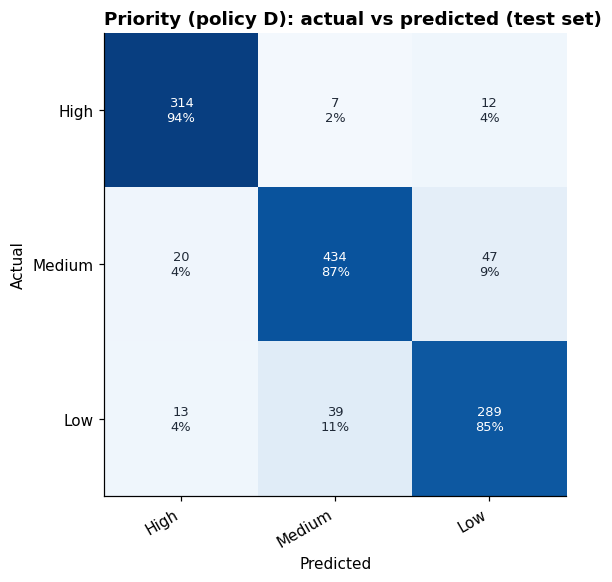

In [13]:
cm_pri = plot_confusion(test["priority"], test["pred_priority"], PRIORITIES, PRIORITIES,
                        f"Priority (policy D): actual vs predicted (test set)", "images/06_priority_confusion.png")

## 6. Error analysis and confidence

Accuracy alone does not say *where* the model fails or whether its confidence can be trusted. Three checks: which categories get confused, whether short tickets are harder, and how accurate the model is when it is confident. The last one decides how many tickets could be routed automatically.

In [14]:
# 1) Most common category mix-ups
pairs = []
for i, a in enumerate(CATEGORIES):
    for j, b in enumerate(CATEGORIES):
        if i != j and cm_cat[i, j] > 0:
            pairs.append({"actual": a, "predicted as": b, "tickets": int(cm_cat[i, j]), "% of actual": cm_cat[i, j] / cm_cat[i].sum() * 100})
pairs = pd.DataFrame(pairs).sort_values("tickets", ascending=False).head(5).round(1).reset_index(drop=True)
print("Top category mix-ups:"); print(pairs.to_string(index=False))

# 2) Accuracy by ticket length
test["correct_cat"] = test["category"] == test["pred_category"]
test["length"] = pd.cut(test["n_words"], [0, 12, 20, 30, 1000], labels=["<=12 words", "13-20", "21-30", "31+"])
by_len = test.groupby("length", observed=True)["correct_cat"].agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "tickets"})
print("\nCategory accuracy by ticket length:"); print((by_len.assign(accuracy=by_len["accuracy"] * 100)).round(1).to_string())

# 3) The most confidently wrong tickets
wrong = test[~test["correct_cat"]].sort_values("cat_confidence", ascending=False).head(4)
print("\nMost confidently wrong tickets:")
for _, r in wrong.iterrows():
    print(f"  actual={SHORT[r['category']]:<9} predicted={SHORT[r['pred_category']]:<9} conf={r['cat_confidence']:.0%}")
    print("   ", textwrap.shorten(r["text_lower"], 140))

Top category mix-ups:
            actual        predicted as  tickets  % of actual
   General Inquiry     Technical Issue        6          5.2
 Returns & Refunds Shipping & Delivery        5          2.9
 Returns & Refunds  Billing & Payments        4          2.3
Billing & Payments     Account & Login        3          1.3
   General Inquiry Shipping & Delivery        3          2.6

Category accuracy by ticket length:
            accuracy  tickets
length                       
<=12 words      93.7       63
13-20           98.1      476
21-30           95.0      497
31+             97.1      139

Most confidently wrong tickets:
  actual=General   predicted=Shipping  conf=98%
    delivery problem. hi, my order has been stuck in transit for 3 days.
  actual=General   predicted=Technical conf=98%
    something is not working. hello team, i get an error message when i click on the export tool.
  actual=Billing   predicted=Returns   conf=97%
    urgent: replacement needed. hi, my refund w

At confidence >= 0.80: 90% of tickets can be auto-routed at 97.5% accuracy; the remaining 10% (accuracy 86%) go to a human for a quick check.


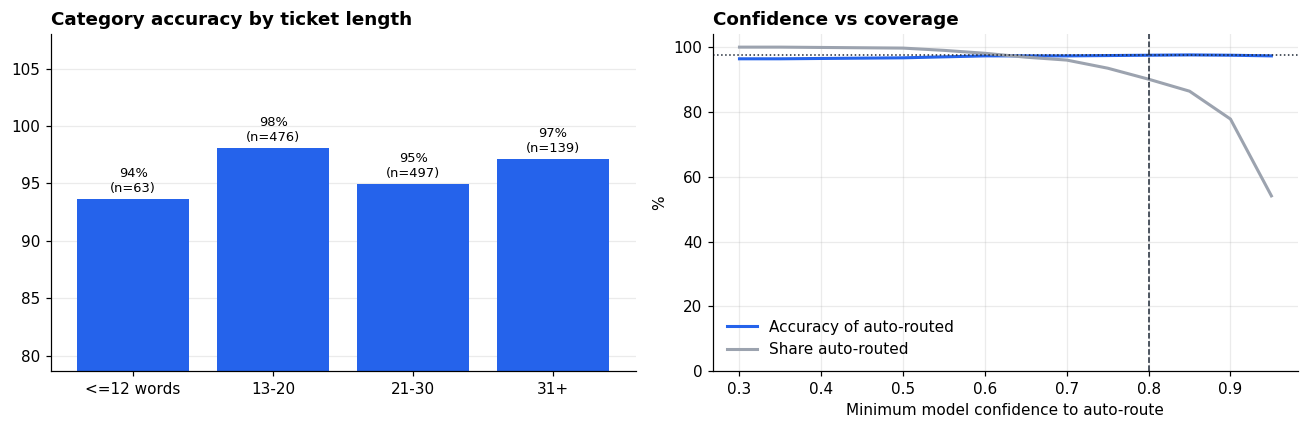

,confidence >=,auto-routed %,accuracy of auto-routed %,accuracy of the rest %
0,0.30,100.0,96.4,NaN
1,0.35,100.0,96.4,NaN
2,0.40,99.9,96.5,0.0
3,0.45,99.8,96.6,0.0
4,0.50,99.7,96.7,0.0
5,0.55,99.0,97.0,41.7
6,0.60,98.1,97.3,50.0
7,0.65,96.9,97.3,69.4
8,0.70,96.0,97.3,74.5
9,0.75,93.5,97.4,82.9


In [15]:
# Confidence-based routing: auto-route confident tickets, send the rest to a human
cuts = np.round(np.arange(0.30, 0.96, 0.05), 2)
rows = []
for c in cuts:
    m = test["cat_confidence"] >= c
    rows.append({"confidence >=": c, "auto-routed %": m.mean() * 100,
                 "accuracy of auto-routed %": test.loc[m, "correct_cat"].mean() * 100 if m.any() else np.nan,
                 "accuracy of the rest %": test.loc[~m, "correct_cat"].mean() * 100 if (~m).any() else np.nan})
routing = pd.DataFrame(rows)
routing[routing.columns[1:]] = routing[routing.columns[1:]].round(1)
TARGET_ACC = 97.5
ok = routing[routing["accuracy of auto-routed %"] >= TARGET_ACC]
CONF_THRESHOLD = float(ok["confidence >="].min()) if len(ok) else 0.90
row = routing[routing["confidence >="] == CONF_THRESHOLD].iloc[0]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(by_len.index.astype(str), by_len["accuracy"] * 100, color=BLUE)
for i, (a_, n_) in enumerate(zip(by_len["accuracy"], by_len["tickets"])):
    ax[0].text(i, a_ * 100 + 0.6, f"{a_ * 100:.0f}%\n(n={n_})", ha="center", fontsize=8.5)
ax[0].set_ylim(max(0, by_len["accuracy"].min() * 100 - 15), 108); ax[0].set_title("Category accuracy by ticket length"); ax[0].grid(axis="x", visible=False)
ax[1].plot(routing["confidence >="], routing["accuracy of auto-routed %"], color=BLUE, lw=2, label="Accuracy of auto-routed")
ax[1].plot(routing["confidence >="], routing["auto-routed %"], color=GRAY, lw=2, label="Share auto-routed")
ax[1].axvline(CONF_THRESHOLD, color=DARK, ls="--", lw=1); ax[1].axhline(TARGET_ACC, color=DARK, ls=":", lw=1)
ax[1].set_xlabel("Minimum model confidence to auto-route"); ax[1].set_ylabel("%"); ax[1].set_ylim(0, 104)
ax[1].set_title("Confidence vs coverage"); ax[1].legend(frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig("images/07_error_and_confidence.png", bbox_inches="tight"); plt.show()

print(f"At confidence >= {CONF_THRESHOLD:.2f}: {row['auto-routed %']:.0f}% of tickets can be auto-routed at {row['accuracy of auto-routed %']:.1f}% accuracy; "
      f"the remaining {100 - row['auto-routed %']:.0f}% (accuracy {row['accuracy of the rest %']:.0f}%) go to a human for a quick check.")
routing

## 7. Business insights

What the model learned, how work would flow through the queues, and a suggested routing and response-time setup.

Predicted queue composition on the test set (tickets):
pred_priority        High  Medium  Low  Total  % High
pred_category                                        
Billing & Payments     72     104   64    240    30.0
Technical Issue       110     102   55    267    41.0
Account & Login        73      75   34    182    40.0
Shipping & Delivery    57     100   52    209    27.0
Returns & Refunds      30      81   59    170    18.0
General Inquiry         5      18   84    107     5.0

Technical Issue generates the most High-priority work (32% of all High tickets); Technical Issue has the highest High rate (41%).


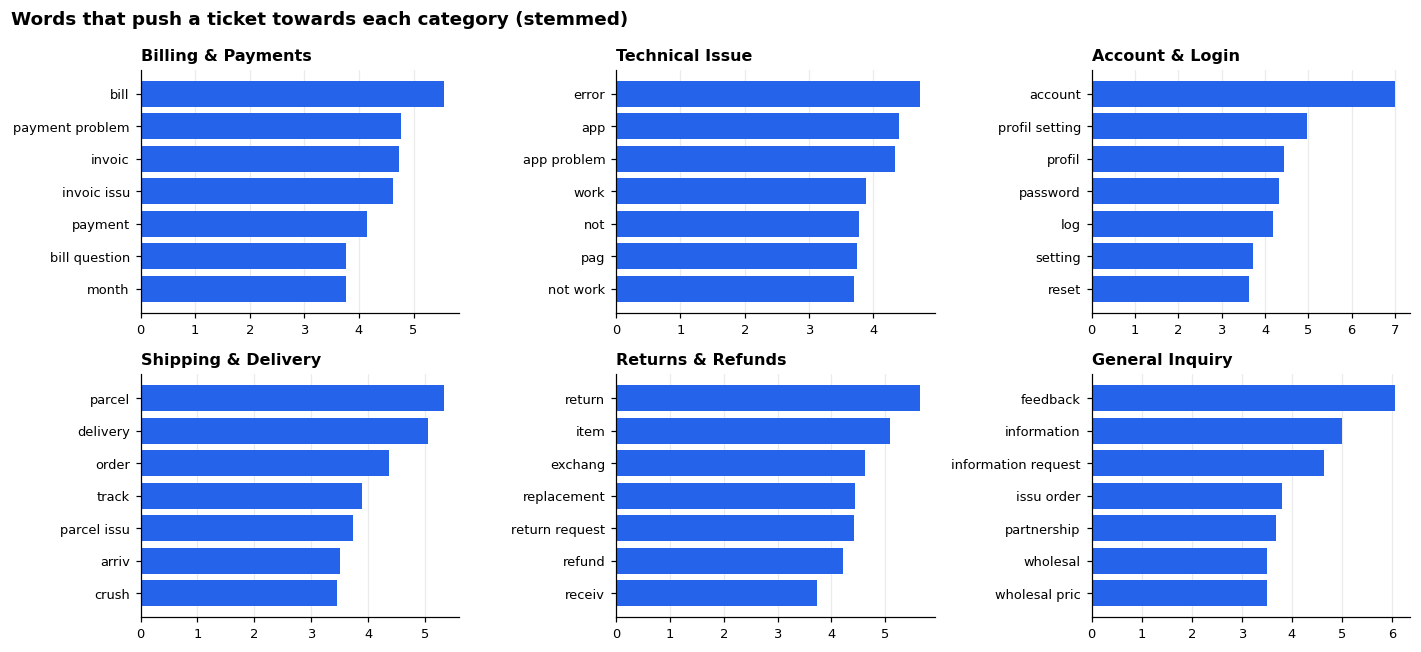

In [16]:
# Interpretation model: a plain logistic regression so the words behind each category can be read directly
interp = Pipeline([("tfidf", tfidf()), ("clf", LogisticRegression(C=10, max_iter=2000))]).fit(train["clean_text"], train["category"])
terms = np.array(interp.named_steps["tfidf"].get_feature_names_out())
coefs = interp.named_steps["clf"].coef_
top_terms = {c: terms[np.argsort(coefs[i])[::-1][:7]] for i, c in enumerate(interp.named_steps["clf"].classes_)}

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, c in zip(axes.ravel(), CATEGORIES):
    i = list(interp.named_steps["clf"].classes_).index(c)
    idx = np.argsort(coefs[i])[::-1][:7][::-1]
    ax.barh(terms[idx], coefs[i][idx], color=BLUE); ax.set_title(c, fontsize=10.5); ax.grid(axis="y", visible=False)
    ax.tick_params(labelsize=8.5)
fig.suptitle("Words that push a ticket towards each category (stemmed)", x=0.01, ha="left", fontweight="bold", fontsize=12)
plt.tight_layout(); plt.savefig("images/08_top_terms.png", bbox_inches="tight"); plt.show()

queue = pd.crosstab(test["pred_category"], test["pred_priority"])[PRIORITIES].loc[CATEGORIES]
queue["Total"] = queue.sum(1); queue["% High"] = (queue["High"] / queue["Total"] * 100).round(0)
print("Predicted queue composition on the test set (tickets):")
print(queue.to_string())
share_high = queue["High"] / queue["High"].sum()
print(f"\n{share_high.idxmax()} generates the most High-priority work ({share_high.max():.0%} of all High tickets); "
      f"{queue['% High'].idxmax()} has the highest High rate ({queue['% High'].max():.0f}%).")

In [17]:
ROUTING = pd.DataFrame({
    "Category":             CATEGORIES,
    "Route to":             ["Billing team", "Technical support", "Account security", "Logistics desk", "Returns desk", "Customer success"],
    "High: first reply":    ["1 hour"] * 6,
    "Medium: first reply":  ["8 hours"] * 6,
    "Low: first reply":     ["24 hours"] * 6,
    "Special handling":     ["Check for duplicate charges / fraud first", "Page on-call engineer if several High tickets arrive together",
                             "Treat 'hacked' tickets as security incidents", "Contact the courier the same day for lost parcels",
                             "Escalate safety-related defects to quality team", "Forward partnership / bulk-order leads to sales"],
}).set_index("Category")
ROUTING   # Teams and response times are suggestions for illustration, not measured business data

,Route to,High: first reply,Medium: first reply,Low: first reply,Special handling
Category,,,,,
Billing & Payments,Billing team,1 hour,8 hours,24 hours,Check for duplicate charges / fraud first
Technical Issue,Technical support,1 hour,8 hours,24 hours,Page on-call engineer if several High tickets arrive together
Account & Login,Account security,1 hour,8 hours,24 hours,Treat 'hacked' tickets as security incidents
Shipping & Delivery,Logistics desk,1 hour,8 hours,24 hours,Contact the courier the same day for lost parcels
Returns & Refunds,Returns desk,1 hour,8 hours,24 hours,Escalate safety-related defects to quality team
General Inquiry,Customer success,1 hour,8 hours,24 hours,Forward partnership / bulk-order leads to sales


## 8. A working triage function

`triage_ticket()` takes a raw subject and body and returns everything a support agent needs: category, confidence, priority, team, response-time target, and whether a human should double-check it. It reuses exactly the same text preparation as training.

In [18]:
def triage_ticket(subject, body=""):
    text = clean_text(prepare_text(subject, body))
    cp = cat_model.predict_proba([text])[0]
    category = cat_model.classes_[cp.argmax()]; conf = float(cp.max())
    pp = pri_model.predict_proba([text])[0]
    p_high = float(pp[list(pri_model.classes_).index("High")])
    priority = apply_threshold(pp.reshape(1, -1), pri_model.classes_, T_HIGH)[0]
    return {"category": category, "category_confidence": round(conf, 2), "priority": priority, "P(High)": round(p_high, 2),
            "route_to": ROUTING.loc[category, "Route to"], "first_reply_target": ROUTING.loc[category, f"{priority}: first reply"],
            "needs_human_check": conf < CONF_THRESHOLD}

examples = [
    ("Charged twice!", "I was charged $89.99 twice for my subscription. Please fix this ASAP."),
    ("Cannot log in", "I think someone hacked my account, there are logins from another country."),
    ("Question about shipping", "Do you ship to Canada? No rush."),
    ("Return request", "The headphones I received are the wrong colour. How do I exchange them?"),
    ("App crashes", "The mobile app crashes every time I open it and our whole team is blocked today."),
    ("Feedback", "Just wanted to say the new website looks great, thanks!"),
]
demo = pd.DataFrame([{"ticket": f"{s}: {b}"[:62] + "...", **triage_ticket(s, b)} for s, b in examples])
demo

,ticket,category,category_confidence,priority,P(High),route_to,first_reply_target,needs_human_check
0,Charged twice!: I was charged $89.99 twice for my subscription...,Billing & Payments,0.96,High,0.96,Billing team,1 hour,False
1,"Cannot log in: I think someone hacked my account, there are lo...",Account & Login,0.98,High,0.80,Account security,1 hour,False
2,Question about shipping: Do you ship to Canada? No rush....,Shipping & Delivery,0.83,Low,0.00,Logistics desk,24 hours,False
3,Return request: The headphones I received are the wrong colour...,Returns & Refunds,0.98,Low,0.01,Returns desk,24 hours,False
4,App crashes: The mobile app crashes every time I open it and o...,Technical Issue,0.94,High,0.61,Technical support,1 hour,False
5,"Feedback: Just wanted to say the new website looks great, than...",General Inquiry,0.94,Low,0.02,Customer success,24 hours,False


In [19]:
# ---------- save all outputs ----------
cols = ["ticket_id", "created_at", "subject", "category", "pred_category", "cat_confidence", "priority", "pred_priority", "p_high"]
out = test[cols].rename(columns={"category": "actual_category", "priority": "actual_priority"})
out["cat_confidence"] = out["cat_confidence"].round(3); out["p_high"] = out["p_high"].round(3)
out.to_csv("outputs/test_predictions.csv", index=False)

cat_cv_out = cat_cv.round(4); cat_cv_out.to_csv("outputs/category_model_comparison.csv")
pri_out = pd.concat([pri_cv.add_suffix("_cv"), pri_test.add_suffix("_test")], axis=1).round(4)
pri_out.to_csv("outputs/priority_policy_comparison.csv")
report_cat.loc[CATEGORIES + ["macro avg"]].round(4).to_csv("outputs/category_classification_report.csv")
report_pri.loc[PRIORITIES + ["macro avg"]].round(4).to_csv("outputs/priority_classification_report.csv")
routing.to_csv("outputs/confidence_routing_table.csv", index=False)
ROUTING.to_csv("outputs/routing_and_response_targets.csv")
demo.to_csv("outputs/triage_demo.csv", index=False)
print("Saved:", ", ".join(sorted(os.listdir("outputs"))))

Saved: category_classification_report.csv, category_model_comparison.csv, confidence_routing_table.csv, priority_classification_report.csv, priority_policy_comparison.csv, routing_and_response_targets.csv, test_predictions.csv, triage_demo.csv


## 9. Summary

| | Result (held-out test set, 1,175 tickets) |
|---|---|
| **Category model** | Linear SVM: **96.4% accuracy**, macro-F1 96.1% (majority-class baseline 22.1%) |
| **Priority policy** | ML + High-recall threshold (P(High) ≥ 0.41): catches **94% of High tickets** at 90% precision, macro-F1 88.2% |
| **Keyword rules only** | Catch 85% of High tickets at 79% precision, macro-F1 75.5% |
| **Auto-routing** | At confidence ≥ 0.80, 90% of tickets can be routed automatically at 97.5% accuracy; the rest go to a human check |

**Reading these numbers honestly**

- The data is simulated and built from templates, so absolute scores are optimistic. About 3% of category labels were deliberately flipped, which caps achievable category accuracy near 97%. On real tickets, expect lower scores and re-check the model leaderboard.
- Priority is the harder task (89% macro-F1 for plain ML) because people write "urgent" on trivial tickets and stay calm about serious ones. That is why the notebook tunes for **High-ticket recall** instead of overall accuracy.
- The High-priority threshold was chosen on training cross-validation only. Test recall (94.3%) landed just under the 95% target; with about 333 High tickets in the test set, a swing of 1-2 points is normal sampling noise, so a production threshold should keep a small safety margin.
- Plain ML (policy B) already catches 94.6% of High tickets, so the threshold does not beat it on this data. Its value is that it is an adjustable dial: lower it to catch more High tickets, raise it to cut false alarms.
- Team names and response times are suggestions for illustration, not measured business data.

**Next steps:** retrain on real tickets, add a "needs review" queue for low-confidence tickets, and refresh the model on a schedule because ticket wording drifts over time.